In [ ]:
# Goal: get a csv file with all goals in the format of goal_formatting_headers.csv

# Challenges:
# - getting names consistent throughout years (some names may be different year to year

# Date Summary:
# Have goals, assists, and goal order for WFL24/25, WFL25/26 seasons

#TODO
# clean data 
# make some cool graphics on matplotlib

In [75]:
import pandas as pd
import matplotlib.pyplot as plt


In [76]:
# 25/26 season
goals_2526_df = pd.read_csv("WFL2526_goals/WFL2526_goals.csv")

goals_2526_df["assisting_player"] = goals_2526_df["assisting_player"].fillna("No Assist")

# goals_2526_df.to_csv('WFL_master_goals.csv', mode='a', header=True, index=False)

goals_2526_df.head(10)

#25/26 season has correct number of goals


,season,gameday,scoring_player,team,game_slot,assisting_player,season_goal_order,Notes
0,WFL2526,GameDay1,Micah Oslund,Sports Experts,early,Etnik Tarakaj,1,NaN
1,WFL2526,GameDay1,Kieran Halliday,Good Vibes FC,early,Evan Libke,2,NaN
2,WFL2526,GameDay1,Larissa Winslade,Good Vibes FC,early,Evan Libke,3,NaN
3,WFL2526,GameDay1,Harrison Kwok,Sports Experts,early,Etnik Tarakaj,4,NaN
4,WFL2526,GameDay1,Gabe Mahamad,Good Vibes FC,early,Evan Libke,5,NaN
5,WFL2526,GameDay1,Harrison Kwok,Sports Experts,early,Ben Warburton,6,NaN
6,WFL2526,GameDay1,Shamus Inglis,Sports Experts,early,Harrison Kwok,7,NaN
7,WFL2526,GameDay1,Juan Pablo Hererra,Good Vibes FC,early,Derek Celi,8,NaN
8,WFL2526,GameDay1,Jason Sealy,Riverdale FC,late,No Assist,9,NaN
9,WFL2526,GameDay1,Mark Chandler,Grizzlies FC,late,Jesse Latoski,10,NaN


In [ ]:
#24/25 season
# did the formatting for this year with a python notebook but then manually went through and added assists
goals_2425_df = pd.read_csv("WFL2425_goals/WFL2425_goals_with_assists.csv") 

# i think i wont deal with duplicate names right now
goals_2425_df["assisting_player"] = goals_2425_df["assisting_player"].fillna("No Assist")

# replace Semis with GameDay16 and Finals with GameDay17
goals_2425_df["gameday"] = goals_2425_df["gameday"].str.replace("Semis", "GameDay16", regex=False)
goals_2425_df["gameday"] = goals_2425_df["gameday"].str.replace("Finals", "GameDay17", regex=False)

# change team name
goals_2425_df["team"] = goals_2425_df["team"].str.replace("RDFC", "Riverdale FC", regex=False)

# missing one goal from the season (have recorded 256/257 goals) -> not going to look lol sorry

# lets add now to master
# goals_2425_df.to_csv('WFL_master_goals.csv', mode='a', header=False, index=False)

goals_2425_df.head(10)

,season,gameday,scoring_player,team,game_slot,assisting_player,season_goal_order,notes
0,WFL2425,GameDay1,Matt Murphy,North 60,early,No Assist,1,NaN
1,WFL2425,GameDay1,Tyler Milton,Double Doubles,early,No Assist,2,half court banger
2,WFL2425,GameDay1,Mark Chandler,Double Doubles,early,Tyler Milton,3,NaN
3,WFL2425,GameDay1,Travis Banks,Double Doubles,early,Caleb Kelly,4,belly slide celly
4,WFL2425,GameDay1,Dom Pehar,North 60,early,Kyan Morrison,5,NaN
5,WFL2425,GameDay1,Caleb Kelly,Double Doubles,early,Mark Chandler,6,NaN
6,WFL2425,GameDay1,Own goal,North 60,early,No Assist,7,NaN
7,WFL2425,GameDay1,Jesse Latoski,Riverdale FC,late,Owen Hedstrom-Langford,8,NaN
8,WFL2425,GameDay1,Tarek Bos,Riverdale FC,late,Marten Sealy,9,nice marty moves
9,WFL2425,GameDay1,Etnik Taraku,Sports Experts,late,No Assist,10,pen


In [84]:
# 23/24 season
# this year doesn't have goals for final games
# this will take a bit more work I think
# have 204/214 goals for this year, ill do some quick digging
# okay looks like some players who joined a team late didn't get added to rosters so they got left out of the algorithm
# not going to work on this now but for example Boris Hoefs 2 goals on last game day were left out
goals_2324_df = pd.read_csv("WFL2324_goals/WFL2324_goals_googlesheets_download.csv") 

# replace header names
goals_2324_df.columns = ['gameday', 'scoring_player', 'team', 'goal_num', 'game_slot']

# remove column
goals_2324_df = goals_2324_df.drop(columns='goal_num')

# add columns (season, assisting_player, season_goal_order, notes)
goals_2324_df['season'] = "WFL2324"
goals_2324_df.insert(0, 'season', goals_2324_df.pop('season')) # putting season as first column
goals_2324_df['assisting_player'] = "Data not avaliable"
goals_2324_df['season_goal_order'] = range(1, len(goals_2324_df) + 1) # no order within games but order of gamedays are still in tact
goals_2324_df['notes'] = ""

# goals_2324_df.to_csv('WFL_master_goals.csv', mode='a', header=False, index=False)

goals_2324_df.head(10)

,season,gameday,scoring_player,team,game_slot,assisting_player,season_goal_order,notes
0,WFL2324,GameDay1,Cody Reaume,North 60,early,Data not avaliable,1,
1,WFL2324,GameDay1,Domagoj Pehar,North 60,early,Data not avaliable,2,
2,WFL2324,GameDay1,Domagoj Pehar,North 60,early,Data not avaliable,3,
3,WFL2324,GameDay1,Marek Boulerice,North 60,early,Data not avaliable,4,
4,WFL2324,GameDay1,Mark Chandler,North 60,early,Data not avaliable,5,
5,WFL2324,GameDay1,Cody Adams,Timbits,early,Data not avaliable,6,
6,WFL2324,GameDay1,Daniel Phillips,Timbits,early,Data not avaliable,7,
7,WFL2324,GameDay1,Evan Howells,Timbits,early,Data not avaliable,8,
8,WFL2324,GameDay1,Matt Thompson,Timbits,early,Data not avaliable,9,
9,WFL2324,GameDay1,Harrison Kwok,Riverdale FC,late,Data not avaliable,10,


In [79]:
# 22/23 Season
#! going to add this season after I get rosters for names
# goals_2223_df = pd.read_csv("WFL2223_goals/WFL2223_goals.csv") 
# ahhh naming will be a Biatch

# goals_2223_df.head(10)

In [111]:
open('WFL_master_goals.csv', 'w').close()

seasons_df = [goals_2526_df, goals_2425_df, goals_2324_df]

# Combine them vertically
combined_seasons_df = pd.concat(seasons_df, axis=0, ignore_index=True) # combine seasons

# massage the combined seasons
combined_seasons_df["scoring_player"] = combined_seasons_df["scoring_player"].str.replace("Michah Oslund", "Micah Oslund", regex=False)
combined_seasons_df["scoring_player"] = combined_seasons_df["scoring_player"].str.replace("Mohamed Abasse Dahalani", "Mohamed Dahalani", regex=False)
combined_seasons_df["scoring_player"] = combined_seasons_df["scoring_player"].str.replace("Domagoj Pehar", "Dom Pehar", regex=False)
combined_seasons_df["scoring_player"] = combined_seasons_df["scoring_player"].str.replace("Juan Pablo Herrera", "Juan Pablo Hererra", regex=False)
combined_seasons_df["scoring_player"] = combined_seasons_df["scoring_player"].str.replace("Mike Irish", "Michael Irish", regex=False)
combined_seasons_df["scoring_player"] = combined_seasons_df["scoring_player"].str.replace("Etnik Taraku", "Etnik Tarakaj", regex=False)
combined_seasons_df["assisting_player"] = combined_seasons_df["assisting_player"].str.replace("Etnik Tarakau", "Etnik Tarakaj", regex=False)
combined_seasons_df["assisting_player"] = combined_seasons_df["assisting_player"].str.replace("Matthew Lersen", "Matthew Larsen", regex=False)
combined_seasons_df["assisting_player"] = combined_seasons_df["assisting_player"].str.replace("Etnik Taraku", "Etnik Tarakaj", regex=False)
combined_seasons_df["assisting_player"] = combined_seasons_df["assisting_player"].str.replace("Michael Irish ", "Michael Irish", regex=False)

# convert df to csv
combined_seasons_df.to_csv('WFL_master_goals.csv', mode='a', header=True, index=False) # add to csv



master_df = pd.read_csv("WFL_master_goals.csv") 

master_df.head(10)


,season,gameday,scoring_player,team,game_slot,assisting_player,season_goal_order,Notes,notes
0,WFL2526,GameDay1,Micah Oslund,Sports Experts,early,Etnik Tarakaj,1,NaN,NaN
1,WFL2526,GameDay1,Kieran Halliday,Good Vibes FC,early,Evan Libke,2,NaN,NaN
2,WFL2526,GameDay1,Larissa Winslade,Good Vibes FC,early,Evan Libke,3,NaN,NaN
3,WFL2526,GameDay1,Harrison Kwok,Sports Experts,early,Etnik Tarakaj,4,NaN,NaN
4,WFL2526,GameDay1,Gabe Mahamad,Good Vibes FC,early,Evan Libke,5,NaN,NaN
5,WFL2526,GameDay1,Harrison Kwok,Sports Experts,early,Ben Warburton,6,NaN,NaN
6,WFL2526,GameDay1,Shamus Inglis,Sports Experts,early,Harrison Kwok,7,NaN,NaN
7,WFL2526,GameDay1,Juan Pablo Hererra,Good Vibes FC,early,Derek Celi,8,NaN,NaN
8,WFL2526,GameDay1,Jason Sealy,Riverdale FC,late,No Assist,9,NaN,NaN
9,WFL2526,GameDay1,Mark Chandler,Grizzlies FC,late,Jesse Latoski,10,NaN,NaN


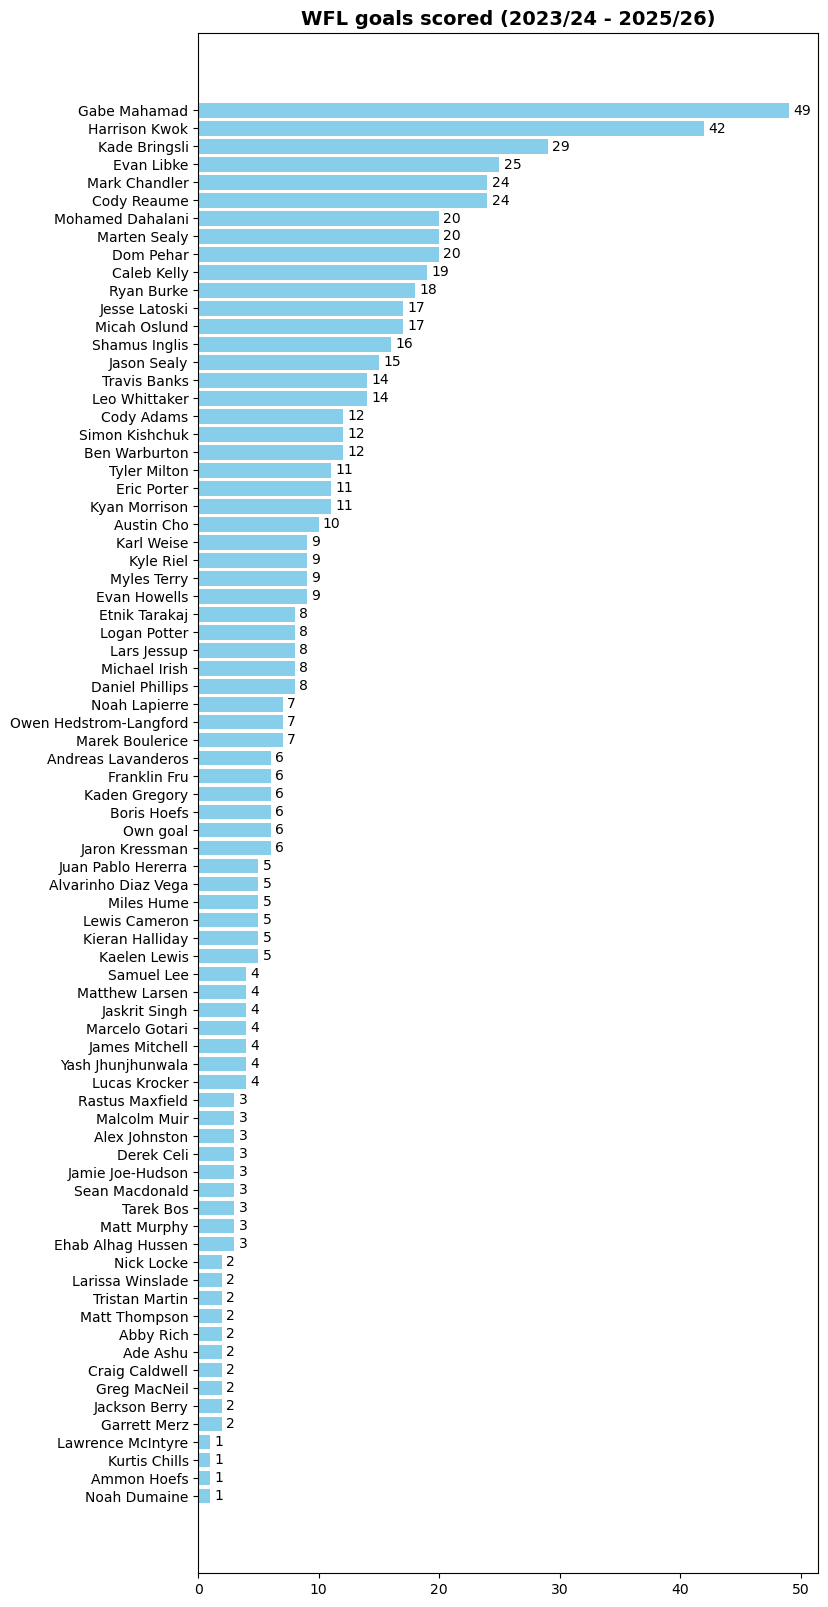

In [ ]:
# first a histogram of goals by player
# plot only top 20 

goal_frequencies = master_df["scoring_player"].value_counts().sort_values()

# 3. Plot the bar chart
fig, ax = plt.subplots(figsize=(8, 20))
bars = ax.barh(goal_frequencies.index, goal_frequencies.values, color="skyblue")

# 4. Add formatting
ax.set_title("WFL goals scored (2023/24 - 2025/26)", fontsize=14, fontweight="bold")
# ax.set_xlabel("Goals", fontsize=12)
# ax.set_ylabel("Player", fontsize=12)
ax.bar_label(bars, padding=3)


# Display chart
plt.show()



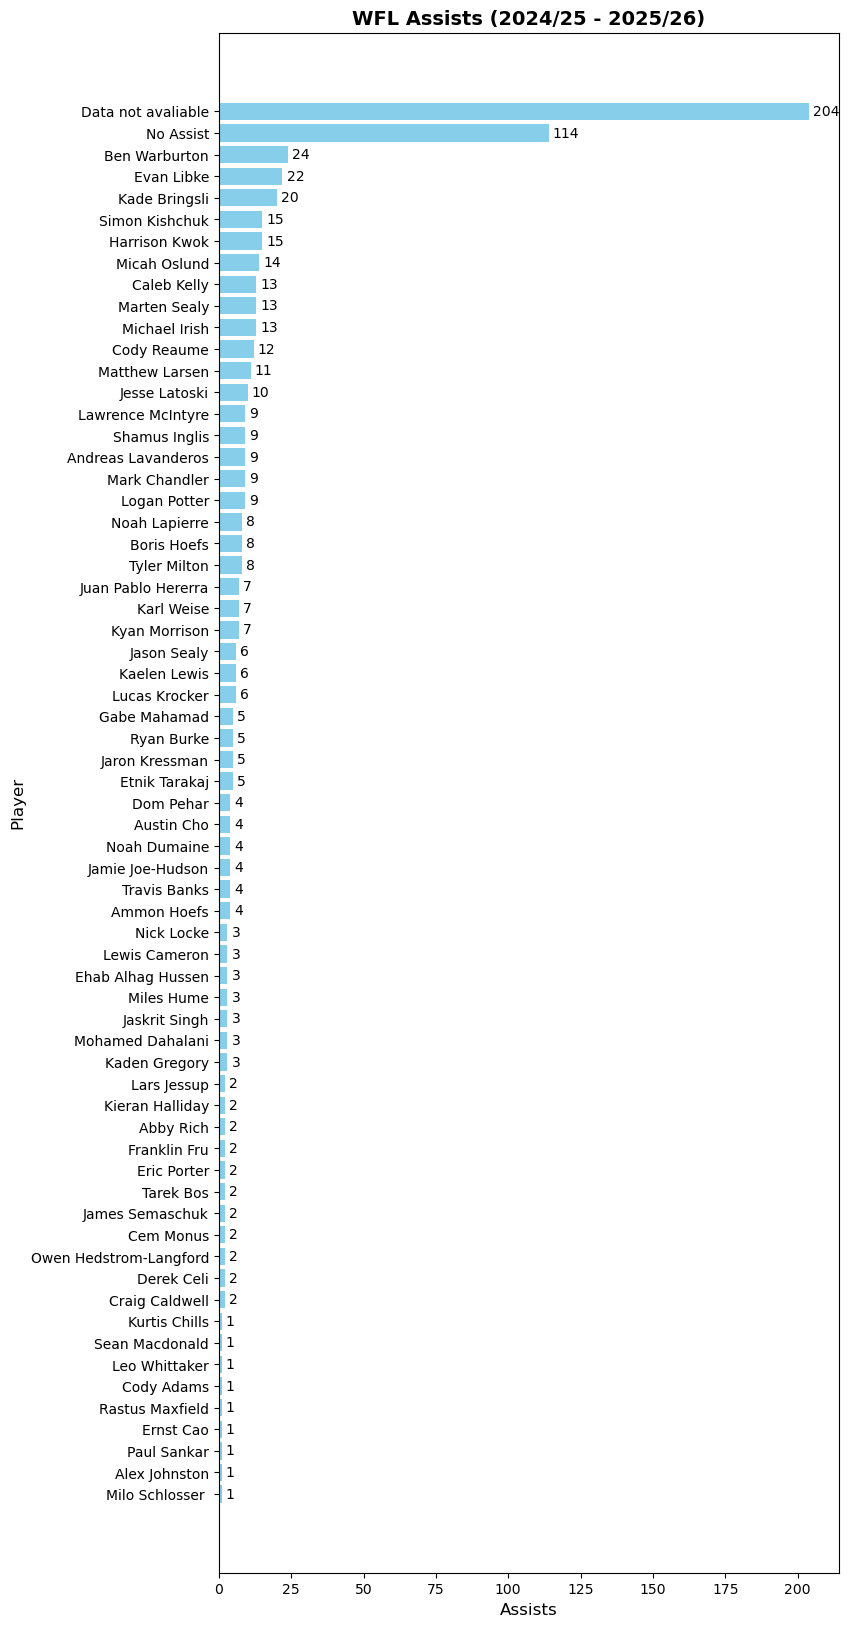

In [113]:
# histogram of assists by player

assist_frequencies = master_df["assisting_player"].value_counts().sort_values()

# 3. Plot the bar chart
fig, ax = plt.subplots(figsize=(8, 20))
bars = ax.barh(assist_frequencies.index, assist_frequencies.values, color="skyblue")

# 4. Add formatting
ax.set_title("WFL Assists (2024/25 - 2025/26)", fontsize=14, fontweight="bold")
ax.set_xlabel("Assists", fontsize=12)
ax.set_ylabel("Player", fontsize=12)
ax.bar_label(bars, padding=3)


# Display chart
plt.show()

